---
title: "The Iris dataset: scatter plots and jittering"
short_title: "Iris"
description: "The Iris dataset and jittering: how to show data in a scatter plot when many points share a value, as an alternative to a histogram or transparency."
---

We will come back to the Iris dataset many times.
For now we look at a plotting technique called "jittering", which makes it possible to show data in a scatter plot even when many points take the same value. It is an alternative to histogram techniques and to adjusting the transparency (the alpha value).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets

iris = datasets.load_iris()
x = iris.data
classes = iris.target

print(x[:5])
print(classes[:5])

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
[0 0 0 0 0]


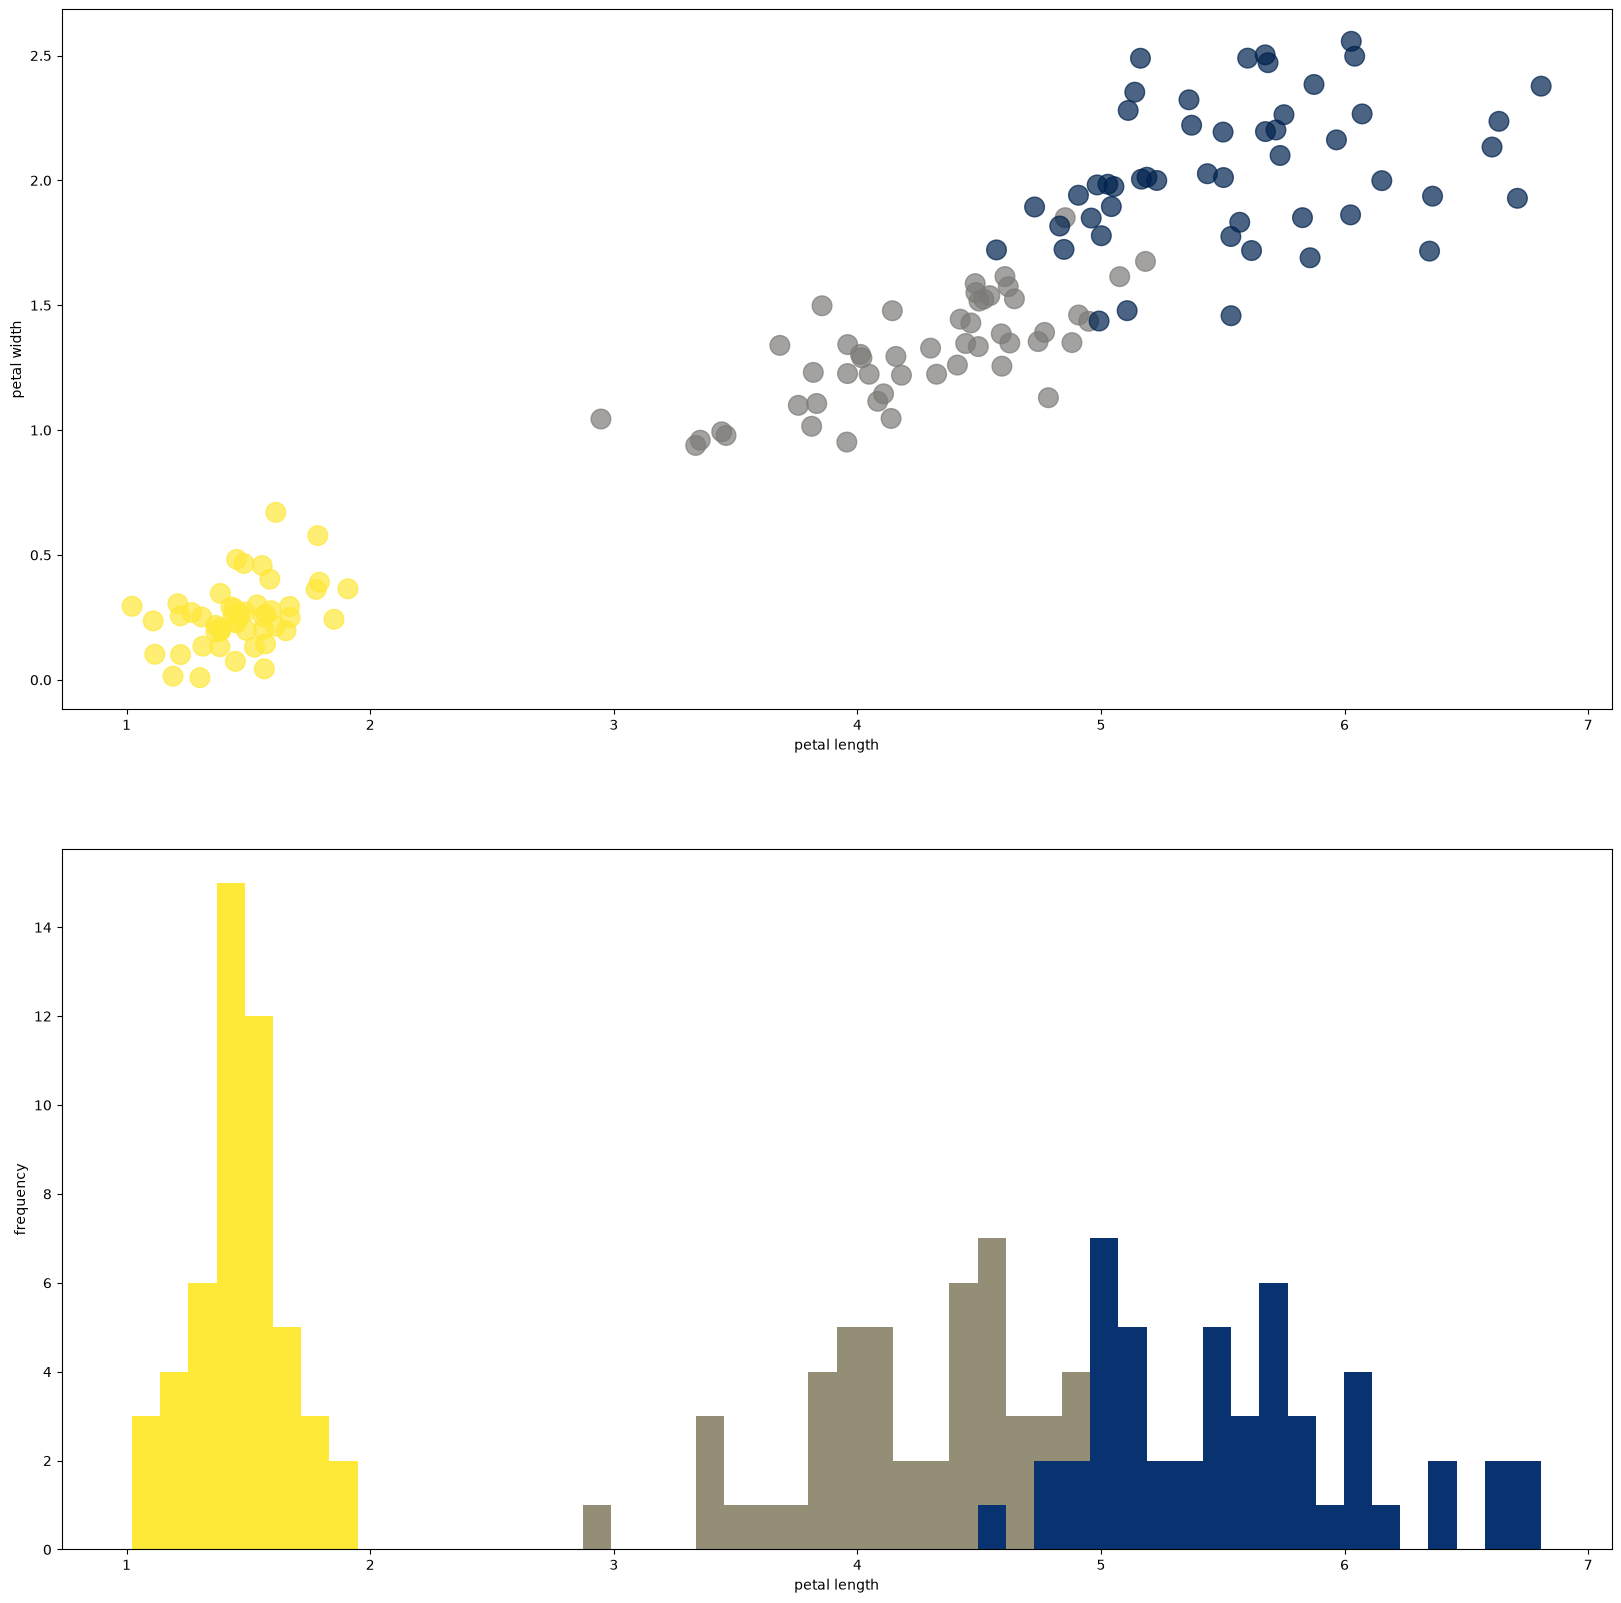

In [2]:
def jitter(xs):
    """Add a little noise to the values so that equal ones do not cover each other up in the scatter plot"""
    b = np.diff(np.sort(xs))
    distance = b[b>0].min()
    return xs + distance * (2*np.random.random(len(xs)) - 1)

fig, (ax1,ax2) = plt.subplots(2, figsize=(20,20))

petlen, petwid = jitter(x[:, 2]), jitter(x[:, 3]) # jitter!
#petlen, petwid = x[:, 2], x[:, 3] # no jitter here, it looks like a grid <---- try the difference!
plmin, plmax = np.min(petlen), np.max(petlen)
cmap = plt.cm.cividis_r

ax1.scatter(petlen, petwid, c=classes, cmap=cmap, alpha=0.7, s=200)
for c in np.unique(classes):
    # spread classes 0, 1, 2 over the colormap; -0.1 keeps class 0 off the very light end
    ax2.hist(petlen[classes == c], range=(plmin,plmax), bins=50, color=cmap(c/2-0.1))

ax2.set_xlabel("petal length")
ax2.set_ylabel("frequency")
ax1.set_xlabel("petal length")
ax1.set_ylabel("petal width")

plt.show()